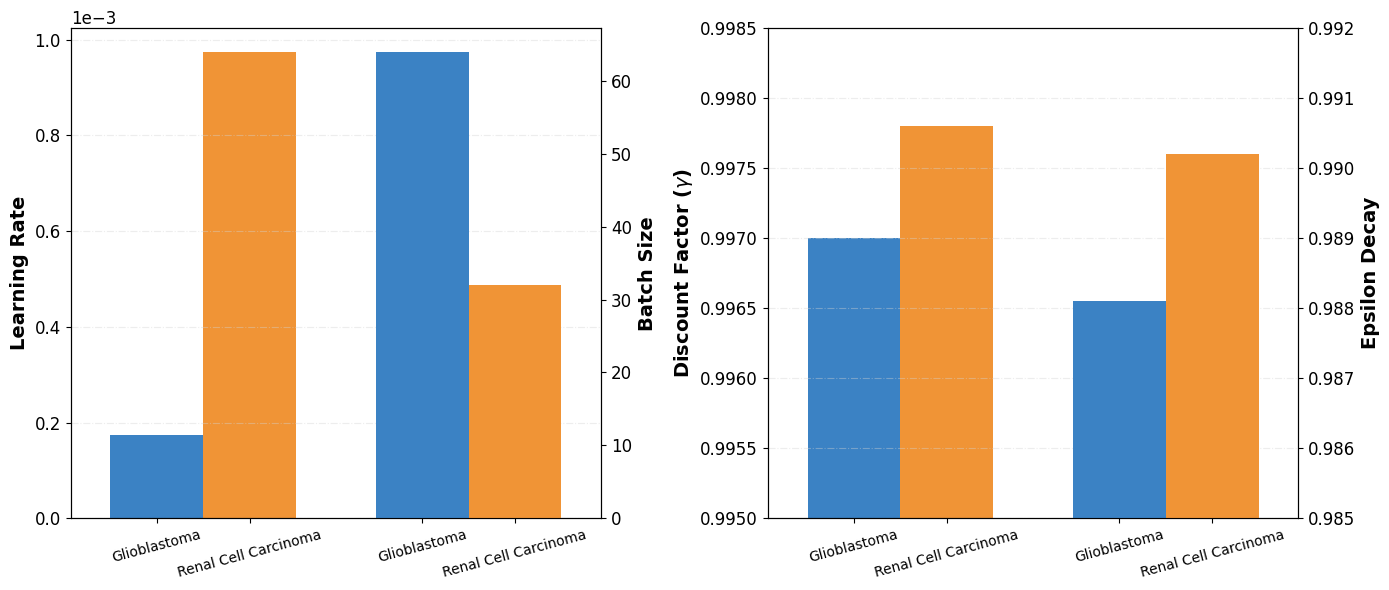

In [3]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Extract data from the LaTeX table
pathologies = ['Glioblastoma', 'Renal Cell Carcinoma']
learning_rate = [1.735e-4, 9.752e-4]
batch_size = [64, 32]
gamma = [0.9970, 0.9978]
epsilon_decay = [0.9881, 0.9902]

# 2. Style configuration
color_blue = '#3b82c4'   # Represents Glioblastoma
color_orange = '#f09436' # Represents Renal Cell Carcinoma
width = 0.35             
x = np.arange(2)         # We now have 2 groups: Metric 1 (Left) and Metric 2 (Right)

# Labels sequence matching the new data mapping
tick_positions = [x[0] - width/2, x[0] + width/2, x[1] - width/2, x[1] + width/2]
tick_labels = [pathologies[0], pathologies[1], pathologies[0], pathologies[1]]

# Create the 1x2 subplot figure
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# ==========================================
# PLOT 1: Learning Rate & Batch Size
# ==========================================
ax1_right = ax1.twinx()

# Group 0 (Left Cluster): Learning Rate (uses Left Axis ax1)
ax1.bar(x[0] - width/2, learning_rate[0], width, color=color_blue)   # Glioblastoma LR
ax1.bar(x[0] + width/2, learning_rate[1], width, color=color_orange) # Renal LR

# Group 1 (Right Cluster): Batch Size (uses Right Axis ax1_right)
ax1_right.bar(x[1] - width/2, batch_size[0], width, color=color_blue)   # Glioblastoma BS
ax1_right.bar(x[1] + width/2, batch_size[1], width, color=color_orange) # Renal BS

# Left Axis - Learning Rate
ax1.set_ylabel('Learning Rate', color="black", fontsize=14, fontweight='bold')
ax1.tick_params(axis='y', labelcolor="black", labelsize=12)
ax1.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
ax1.yaxis.get_offset_text().set_color('black') # Changed to black to avoid color confusion
ax1.yaxis.get_offset_text().set_fontsize(12)

# Right Axis - Batch Size
ax1_right.set_ylabel('Batch Size', color="black", fontsize=14, fontweight='bold')
ax1_right.tick_params(axis='y', labelcolor="black", labelsize=12)

# Styling and Grid
ax1.set_xticks(tick_positions)
ax1.set_xticklabels(tick_labels, fontsize=10, rotation=15, ha='center') 
ax1.set_xlim(-0.5, 1.5) # Keeps the clusters centered
ax1.grid(axis='y', linestyle='-.', alpha=0.4, color='lightgray')

plt.subplots_adjust(wspace=0.4)

# ==========================================
# PLOT 2: Discount Factor & Epsilon Decay
# ==========================================
ax2_right = ax2.twinx()

base_gamma, base_eps = 0.9900, 0.9800

# Group 0 (Left Cluster): Gamma (uses Left Axis ax2)
ax2.bar(x[0] - width/2, gamma[0] - base_gamma, width, bottom=base_gamma, color=color_blue)   # Glioblastoma Gamma
ax2.bar(x[0] + width/2, gamma[1] - base_gamma, width, bottom=base_gamma, color=color_orange) # Renal Gamma

# Group 1 (Right Cluster): Epsilon Decay (uses Right Axis ax2_right)
ax2_right.bar(x[1] - width/2, epsilon_decay[0] - base_eps, width, bottom=base_eps, color=color_blue)   # Glioblastoma Eps
ax2_right.bar(x[1] + width/2, epsilon_decay[1] - base_eps, width, bottom=base_eps, color=color_orange) # Renal Eps

# Left Axis - Gamma
ax2.set_ylabel(r'Discount Factor ($\gamma$)', color="black", fontsize=14, fontweight='bold')
ax2.tick_params(axis='y', labelcolor="black", labelsize=12)
ax2.set_ylim(0.9950, 0.9985) 

# Right Axis - Epsilon Decay
ax2_right.set_ylabel('Epsilon Decay', color="black", fontsize=14, fontweight='bold')
ax2_right.tick_params(axis='y', labelcolor="black", labelsize=12)
ax2_right.set_ylim(0.9850, 0.9920) 

# Styling and Grid
ax2.set_xticks(tick_positions)
ax2.set_xticklabels(tick_labels, fontsize=10, rotation=15, ha='center')
ax2.set_xlim(-0.5, 1.5) # Keeps the clusters centered
ax2.grid(axis='y', linestyle='-.', alpha=0.4, color='lightgray')

# Final layout adjustments
plt.tight_layout()
plt.savefig('pathology_hyperparameters.pdf', format='pdf', bbox_inches='tight')
plt.show()

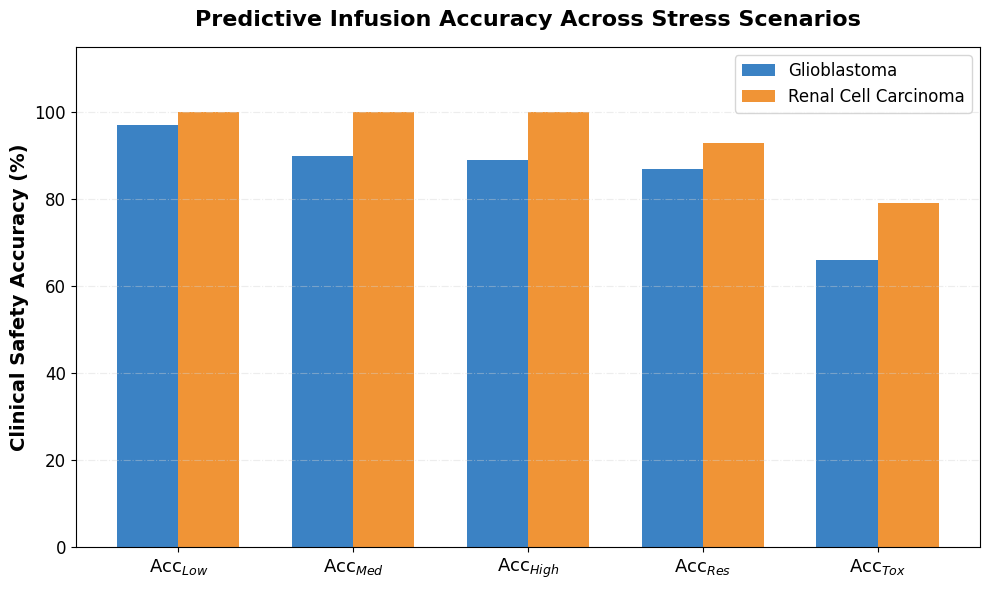

In [4]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Extract data from the LaTeX table
scenarios = ['Acc$_{Low}$', 'Acc$_{Med}$', 'Acc$_{High}$', 'Acc$_{Res}$', 'Acc$_{Tox}$']
glio_acc = [97.0, 90.0, 89.0, 87.0, 66.0]
renal_acc = [100.0, 100.0, 100.0, 93.0, 79.0]

# 2. Style configuration (matching previous plots)
color_blue = '#3b82c4'   # Muted Matplotlib-style blue for Glioblastoma
color_orange = '#f09436' # Muted Matplotlib-style orange for Renal Cell Carcinoma
width = 0.35             # Width of the individual bars

x = np.arange(len(scenarios))  # Label locations

# Create the figure
fig, ax = plt.subplots(figsize=(10, 6))

# ==========================================
# PLOT: Grouped Bars
# ==========================================
bars1 = ax.bar(x - width/2, glio_acc, width, label='Glioblastoma', color=color_blue)
bars2 = ax.bar(x + width/2, renal_acc, width, label='Renal Cell Carcinoma', color=color_orange)

# Styling and Grid
ax.set_title('Predictive Infusion Accuracy Across Stress Scenarios', fontsize=16, fontweight='bold', pad=15)
ax.set_ylabel('Clinical Safety Accuracy (%)', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(scenarios, fontsize=13)
ax.set_ylim(0, 115) # Extended slightly to fit the legend and labels
ax.tick_params(axis='y', labelsize=12)
ax.grid(axis='y', linestyle='-.', alpha=0.4, color='lightgray')

# Add legend
ax.legend(fontsize=12, loc='upper right')

# # Add value labels on top of the bars
# def add_labels(bars):
#     for bar in bars:
#         yval = bar.get_height()
#         ax.text(bar.get_x() + bar.get_width()/2, yval + 1.5, f'{yval:.1f}%', 
#                  ha='center', va='bottom', fontsize=10, fontweight='bold')

# add_labels(bars1)
# add_labels(bars2)

# Final layout adjustments
plt.tight_layout()

plt.savefig('pathology_accuracy.pdf', format='pdf', bbox_inches='tight')

plt.show()

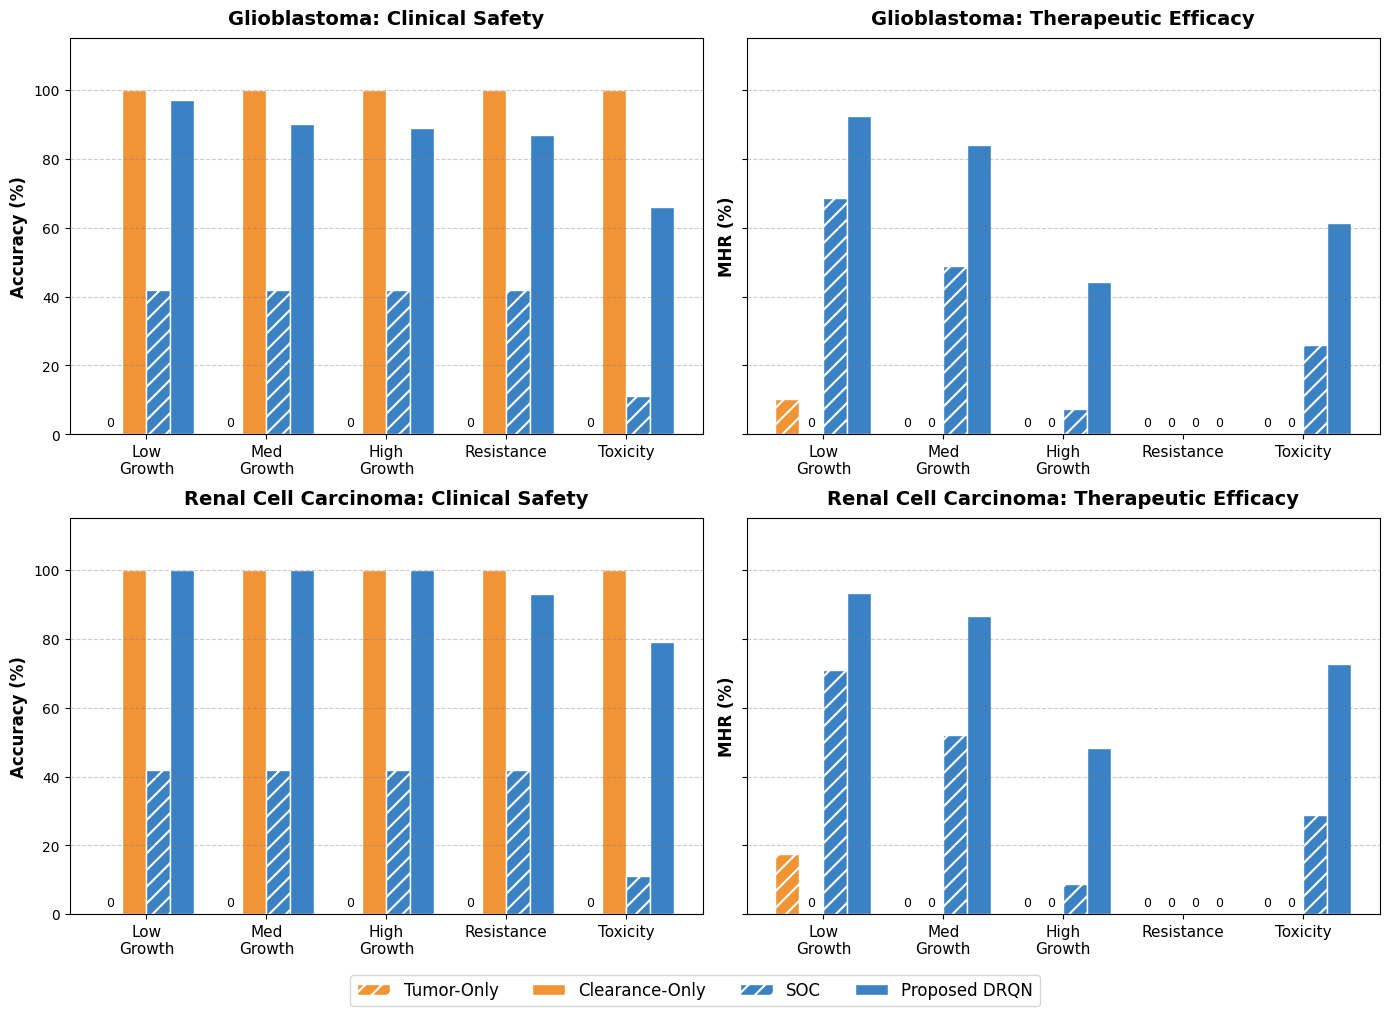

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import os

# ==========================================
# 1. Data Extraction
# ==========================================
scenarios = ['Low\nGrowth', 'Med\nGrowth', 'High\nGrowth', 'Resistance', 'Toxicity']
x = np.arange(len(scenarios))
width = 0.2  # Width of each bar

# Glioblastoma Data
glio_acc = {
    'Tumor-Only': [0.0, 0.0, 0.0, 0.0, 0.0],
    'Clearance-Only': [100.0, 100.0, 100.0, 100.0, 100.0],
    'SOC': [42.0, 42.0, 42.0, 42.0, 11.0],
    'Proposed DRQN': [97.0, 90.0, 89.0, 87.0, 66.0]
}
glio_mhr = {
    'Tumor-Only': [10.4, 0.0, 0.0, 0.0, 0.0],
    'Clearance-Only': [0.0, 0.0, 0.0, 0.0, 0.0],
    'SOC': [68.7, 49.0, 7.3, 0.0, 25.8],
    'Proposed DRQN': [92.4, 84.1, 44.3, 0.0, 61.3]
}

# Renal Cell Carcinoma Data
renal_acc = {
    'Tumor-Only': [0.0, 0.0, 0.0, 0.0, 0.0],
    'Clearance-Only': [100.0, 100.0, 100.0, 100.0, 100.0],
    'SOC': [42.0, 42.0, 42.0, 42.0, 11.0],
    'Proposed DRQN': [100.0, 100.0, 100.0, 93.0, 79.0]
}
renal_mhr = {
    'Tumor-Only': [17.4, 0.0, 0.0, 0.0, 0.0],
    'Clearance-Only': [0.0, 0.0, 0.0, 0.0, 0.0],
    'SOC': [71.0, 52.0, 8.7, 0.0, 28.8],
    'Proposed DRQN': [93.2, 86.5, 48.2, 0.0, 72.8]
}

# Thematic Colors & Hatches
colors = {
    'Tumor-Only': '#f09436',       # Orange
    'Clearance-Only': '#f09436',   # Orange
    'SOC': '#3b82c4',              # Blue
    'Proposed DRQN': '#3b82c4'     # Blue
}

hatches = {
    'Tumor-Only': '//',
    'Clearance-Only': '',
    'SOC': '//',
    'Proposed DRQN': ''
}

# ==========================================
# 2. Plot Construction (2x2 Grid)
# ==========================================
plt.style.use('default')

# Adjust matplotlib parameters to make the white hatches slightly thicker and clearer
plt.rcParams['hatch.linewidth'] = 1.5 

# Removed sharex=True so the x-axis labels appear on all rows
fig, axs = plt.subplots(2, 2, figsize=(14, 10), sharey=True)

def plot_grouped_bars(ax, data_dict, title, ylabel):
    offsets = [-1.5 * width, -0.5 * width, 0.5 * width, 1.5 * width]
    
    for (label, values), offset in zip(data_dict.items(), offsets):
        # Set edgecolor to white to render white hatches and remove the visible black border
        bars = ax.bar(x + offset, values, width, label=label, 
                      color=colors[label], hatch=hatches[label], 
                      edgecolor='white', linewidth=1.0)
        
        # Explicitly showcase the zeros
        for bar, val in zip(bars, values):
            if val == 0.0:
                ax.text(bar.get_x() + bar.get_width()/2, 1.5, '0', 
                        ha='center', va='bottom', fontsize=9, color='black')
    
    ax.set_title(title, fontsize=14, fontweight='bold', pad=10)
    ax.set_ylabel(ylabel, fontsize=12, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(scenarios, fontsize=11)
    ax.set_ylim(0, 115)
    ax.grid(axis='y', linestyle='--', alpha=0.4, color='gray')

# Top Row: Glioblastoma (Safety vs. Efficacy)
plot_grouped_bars(axs[0, 0], glio_acc, 'Glioblastoma: Clinical Safety', 'Accuracy (%)')
plot_grouped_bars(axs[0, 1], glio_mhr, 'Glioblastoma: Therapeutic Efficacy', 'MHR (%)')

# Bottom Row: Renal Cell Carcinoma (Safety vs. Efficacy)
plot_grouped_bars(axs[1, 0], renal_acc, 'Renal Cell Carcinoma: Clinical Safety', 'Accuracy (%)')
plot_grouped_bars(axs[1, 1], renal_mhr, 'Renal Cell Carcinoma: Therapeutic Efficacy', 'MHR (%)')

# Add a single unified legend at the bottom
handles, labels = axs[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4, fontsize=12, bbox_to_anchor=(0.5, -0.02))

plt.tight_layout()
fig.subplots_adjust(bottom=0.08) # Make room for the legend

os.makedirs("results", exist_ok=True)
plt.savefig("results/baseline_comparison_grid.pdf", dpi=300, bbox_inches='tight')
plt.show()

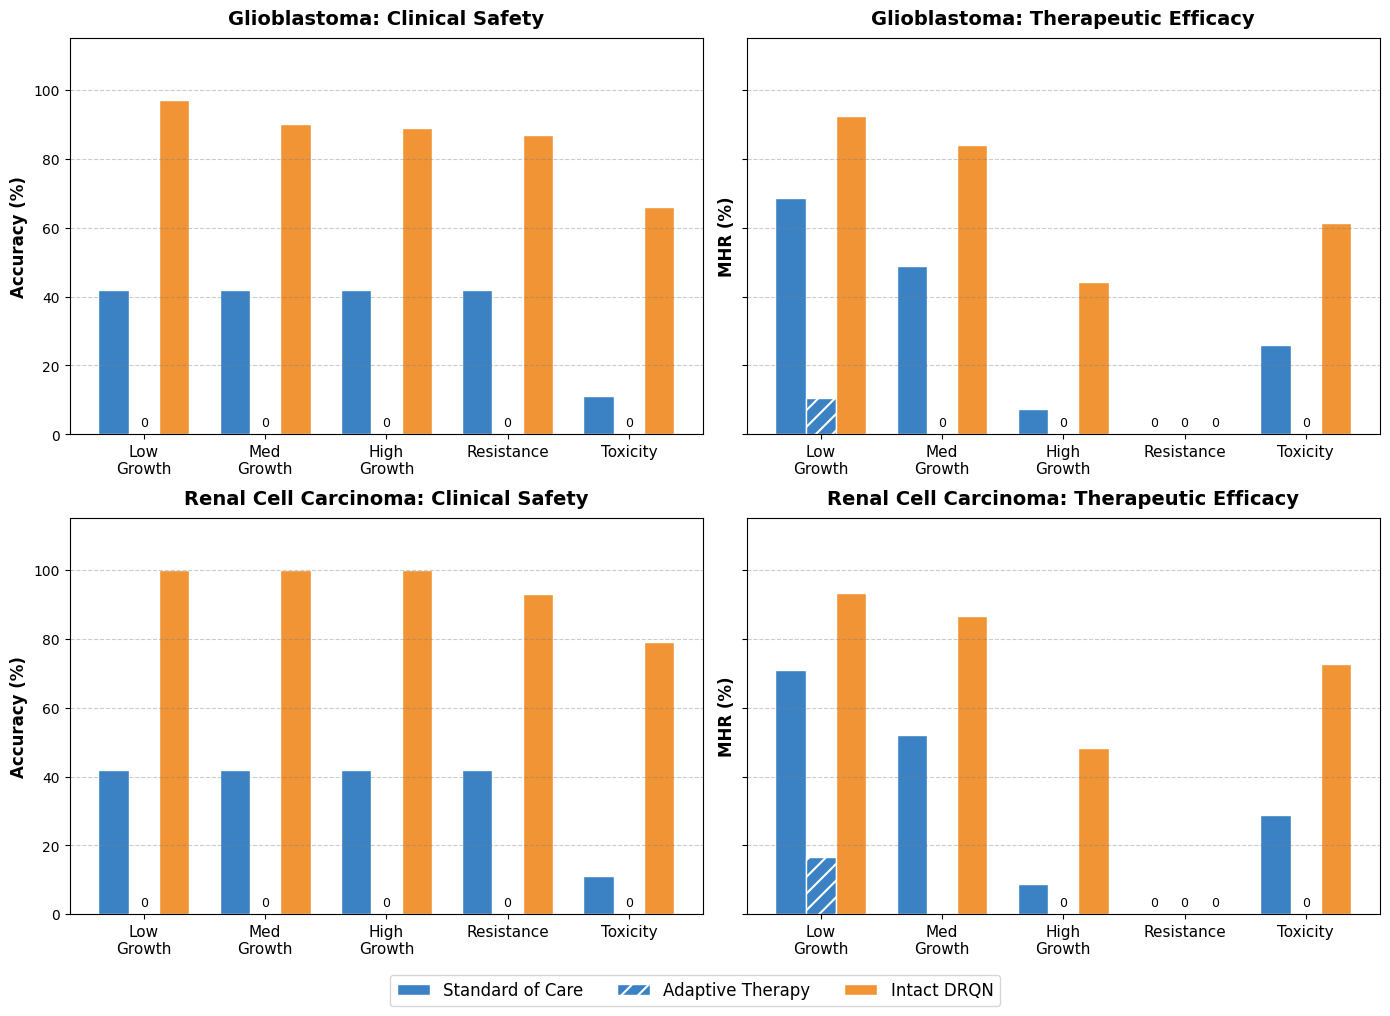

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import os

# ==========================================
# 1. Data Extraction
# ==========================================
scenarios = ['Low\nGrowth', 'Med\nGrowth', 'High\nGrowth', 'Resistance', 'Toxicity']
x = np.arange(len(scenarios))
width = 0.25  # Slightly wider since we only have 3 bars now

# Glioblastoma Data
glio_acc = {
    'Standard of Care': [42.0, 42.0, 42.0, 42.0, 11.0],
    'Adaptive Therapy': [0.0, 0.0, 0.0, 0.0, 0.0],
    'Intact DRQN': [97.0, 90.0, 89.0, 87.0, 66.0]
}
glio_mhr = {
    'Standard of Care': [68.7, 49.0, 7.3, 0.0, 25.8],
    'Adaptive Therapy': [10.6, 0.0, 0.0, 0.0, 0.0],
    'Intact DRQN': [92.4, 84.1, 44.3, 0.0, 61.3]
}

# Renal Cell Carcinoma Data
renal_acc = {
    'Standard of Care': [42.0, 42.0, 42.0, 42.0, 11.0],
    'Adaptive Therapy': [0.0, 0.0, 0.0, 0.0, 0.0],
    'Intact DRQN': [100.0, 100.0, 100.0, 93.0, 79.0]
}
renal_mhr = {
    'Standard of Care': [71.0, 52.0, 8.7, 0.0, 28.8],
    'Adaptive Therapy': [16.7, 0.4, 0.0, 0.0, 0.0],
    'Intact DRQN': [93.2, 86.5, 48.2, 0.0, 72.8]
}

# Thematic Colors & Hatches
colors = {
    'Standard of Care': '#3b82c4',   # Blue
    'Adaptive Therapy': '#3b82c4',   # Orange
    'Intact DRQN': '#f09436'         # Blue
}

hatches = {
    'Standard of Care': '',
    'Adaptive Therapy': '//',
    'Intact DRQN': ''
}

# ==========================================
# 2. Plot Construction (2x2 Grid)
# ==========================================
plt.style.use('default')

# Adjust matplotlib parameters to make the white hatches slightly thicker and clearer
plt.rcParams['hatch.linewidth'] = 1.5 

# Removed sharex=True so the x-axis labels appear on all rows
fig, axs = plt.subplots(2, 2, figsize=(14, 10), sharey=True)

def plot_grouped_bars(ax, data_dict, title, ylabel):
    # Calculate perfectly centered offsets for 3 bars
    offsets = [-width, 0, width]
    
    for (label, values), offset in zip(data_dict.items(), offsets):
        # Set edgecolor to white to render white hatches and remove the visible black border
        bars = ax.bar(x + offset, values, width, label=label, 
                      color=colors[label], hatch=hatches[label], 
                      edgecolor='white', linewidth=1.0)
        
        # Explicitly showcase the zeros
        for bar, val in zip(bars, values):
            if val == 0.0:
                ax.text(bar.get_x() + bar.get_width()/2, 1.5, '0', 
                        ha='center', va='bottom', fontsize=9, color='black')
    
    ax.set_title(title, fontsize=14, fontweight='bold', pad=10)
    ax.set_ylabel(ylabel, fontsize=12, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(scenarios, fontsize=11)
    ax.set_ylim(0, 115)
    ax.grid(axis='y', linestyle='--', alpha=0.4, color='gray')

# Top Row: Glioblastoma (Safety vs. Efficacy)
plot_grouped_bars(axs[0, 0], glio_acc, 'Glioblastoma: Clinical Safety', 'Accuracy (%)')
plot_grouped_bars(axs[0, 1], glio_mhr, 'Glioblastoma: Therapeutic Efficacy', 'MHR (%)')

# Bottom Row: Renal Cell Carcinoma (Safety vs. Efficacy)
plot_grouped_bars(axs[1, 0], renal_acc, 'Renal Cell Carcinoma: Clinical Safety', 'Accuracy (%)')
plot_grouped_bars(axs[1, 1], renal_mhr, 'Renal Cell Carcinoma: Therapeutic Efficacy', 'MHR (%)')

# Add a single unified legend at the bottom (ncol=3 since we have 3 baselines)
handles, labels = axs[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, fontsize=12, bbox_to_anchor=(0.5, -0.02))

plt.tight_layout()
fig.subplots_adjust(bottom=0.08) # Make room for the legend

os.makedirs("results", exist_ok=True)
plt.savefig("results/baseline_comparison_grid.pdf", dpi=300, bbox_inches='tight')
plt.show()

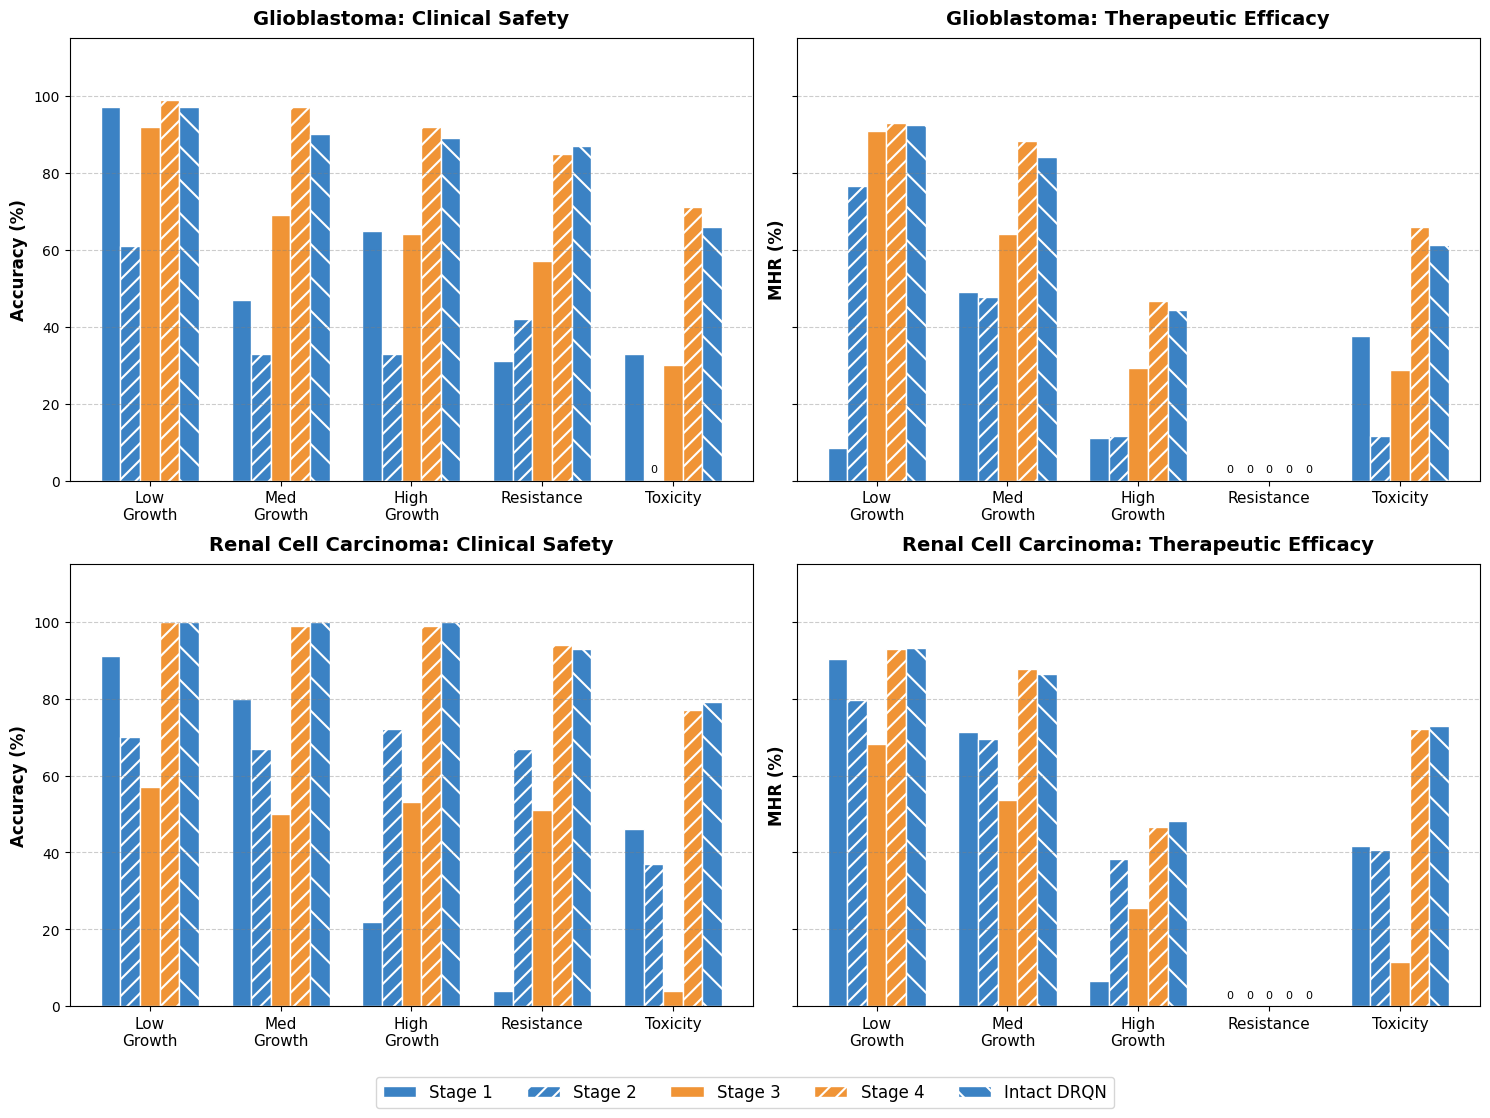

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import os

# ==========================================
# 1. Data Extraction
# ==========================================
scenarios = ['Low\nGrowth', 'Med\nGrowth', 'High\nGrowth', 'Resistance', 'Toxicity']
x = np.arange(len(scenarios))
width = 0.15  # Narrower to fit 5 bars per scenario

# Glioblastoma Data
glio_acc = {
    'Stage 1': [97.0, 47.0, 65.0, 31.0, 33.0],
    'Stage 2': [61.0, 33.0, 33.0, 42.0, 0.0],
    'Stage 3': [92.0, 69.0, 64.0, 57.0, 30.0],
    'Stage 4': [99.0, 97.0, 92.0, 85.0, 71.0],
    'Intact DRQN': [97.0, 90.0, 89.0, 87.0, 66.0]
}
glio_mhr = {
    'Stage 1': [8.4, 49.0, 11.1, 0.0, 37.6],
    'Stage 2': [76.7, 47.8, 11.6, 0.0, 11.7],
    'Stage 3': [90.8, 64.1, 29.3, 0.0, 28.8],
    'Stage 4': [93.0, 88.4, 46.7, 0.0, 65.9],
    'Intact DRQN': [92.4, 84.1, 44.3, 0.0, 61.3]
}

# Renal Cell Carcinoma Data
renal_acc = {
    'Stage 1': [91.0, 80.0, 22.0, 4.0, 46.0],
    'Stage 2': [70.0, 67.0, 72.0, 67.0, 37.0],
    'Stage 3': [57.0, 50.0, 53.0, 51.0, 4.0],
    'Stage 4': [100.0, 99.0, 99.0, 94.0, 77.0],
    'Intact DRQN': [100.0, 100.0, 100.0, 93.0, 79.0]
}
renal_mhr = {
    'Stage 1': [90.4, 71.3, 6.6, 0.0, 41.7],
    'Stage 2': [79.6, 69.4, 38.3, 0.0, 40.6],
    'Stage 3': [68.3, 53.7, 25.5, 0.0, 11.4],
    'Stage 4': [93.0, 87.8, 46.6, 0.0, 72.1],
    'Intact DRQN': [93.2, 86.5, 48.2, 0.0, 72.8]
}

# Thematic Colors & Hatches
# Using a blue gradient for expansion stages, and orange for the Intact DRQN
colors = {
    'Stage 1': '#3b82c4',       # Lightest Blue
    'Stage 2': '#3b82c4',       # Light-Medium Blue
    'Stage 3': '#f09436',       # Medium-Dark Blue
    'Stage 4': '#f09436',       # Darkest Blue
    'Intact DRQN': '#3b82c4'    # Orange
}

hatches = {
    'Stage 1': '',
    'Stage 2': '//',
    'Stage 3': '',
    'Stage 4': '//',
    'Intact DRQN': '\\'
}

# ==========================================
# 2. Plot Construction (2x2 Grid)
# ==========================================
plt.style.use('default')

# Adjust matplotlib parameters to make the white hatches slightly thicker and clearer
plt.rcParams['hatch.linewidth'] = 1.5 

# Removed sharex=True so the x-axis labels appear on all rows
fig, axs = plt.subplots(2, 2, figsize=(15, 11), sharey=True)

def plot_grouped_bars(ax, data_dict, title, ylabel):
    # Calculate perfectly centered offsets for 5 bars
    offsets = [-2 * width, -width, 0, width, 2 * width]
    
    for (label, values), offset in zip(data_dict.items(), offsets):
        bars = ax.bar(x + offset, values, width, label=label, 
                      color=colors[label], hatch=hatches[label], 
                      edgecolor='white', linewidth=1.0)
        
        # Explicitly showcase the zeros
        for bar, val in zip(bars, values):
            if val == 0.0:
                ax.text(bar.get_x() + bar.get_width()/2, 1.5, '0', 
                        ha='center', va='bottom', fontsize=8, color='black')
    
    ax.set_title(title, fontsize=14, fontweight='bold', pad=10)
    ax.set_ylabel(ylabel, fontsize=12, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(scenarios, fontsize=11)
    ax.set_ylim(0, 115)
    ax.grid(axis='y', linestyle='--', alpha=0.4, color='gray')

# Top Row: Glioblastoma (Safety vs. Efficacy)
plot_grouped_bars(axs[0, 0], glio_acc, 'Glioblastoma: Clinical Safety', 'Accuracy (%)')
plot_grouped_bars(axs[0, 1], glio_mhr, 'Glioblastoma: Therapeutic Efficacy', 'MHR (%)')

# Bottom Row: Renal Cell Carcinoma (Safety vs. Efficacy)
plot_grouped_bars(axs[1, 0], renal_acc, 'Renal Cell Carcinoma: Clinical Safety', 'Accuracy (%)')
plot_grouped_bars(axs[1, 1], renal_mhr, 'Renal Cell Carcinoma: Therapeutic Efficacy', 'MHR (%)')

# Add a single unified legend at the bottom (ncol=5 since we have 5 variants)
handles, labels = axs[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=5, fontsize=12, bbox_to_anchor=(0.5, -0.02))

plt.tight_layout()
fig.subplots_adjust(bottom=0.08) # Make room for the legend

os.makedirs("results", exist_ok=True)
plt.savefig("results/spatial_expansion_grid.pdf", dpi=300, bbox_inches='tight')
plt.show()